# Practica de Visualización

Un dataset de NOAA está almacenado en el archivo `data/fb441e62df2d58994928907a91895ec62c2c42e6cd075c2700843b89.csv`. Este es el dataset que utilizaremos para la práctica.

Nota: Los datos para esta práctica forman parte de un dataset perteneciente a The data for this assignment comes from a subset of The National Centers for Environmental Information (NCEI) [Daily Global Historical Climatology Network](https://www1.ncdc.noaa.gov/pub/data/ghcn/daily/readme.txt) (GHCN-Daily). El GHCN-Daily se compone de registros climáticos diarios de miles de estaciones de la superficie terrestre en todo el mundo.

Cada fila en el archivo de datos corresponde a una sola observación.

Nos proporciona las siguientes variables:

- **id** : código de identificación de la estación
- **date** : fecha en formato YYYY-MM-DD (por ejemplo: 2012-01-24 = 24 de enero de 2012)
- **element** : indica el tipo de medición
    - **TMAX** : Temperatura máxima
    - **TMIN** : Temperatura mínima
- **value**: valor de la temperatura (en décimas de grados centígrados)

## Indicaciones

1. Lee la documentación y familiarícese con el conjunto de datos, luego escriba un código python que arroje un gráfico lineal de las temperaturas máximas y mínimas récord por día del año durante el período 2005-2014. El área entre las temperaturas máximas y mínimas récord de cada día debe estar sombreada.
2. Superponga una dispersión de los datos de 2015 para cualquier punto (máximos y mínimos) para los cuales se superó el récord de diez años (2005-2014) máximo o mínimo histórico en 2015.
3. Debes tener cuidado con los días bisiestos (es decir, el 29 de febrero), es totalmente razonable eliminar estos puntos del conjunto de datos para esta visualización.
4. ¡Haz que la imagen sea agradable! Considera problemas como leyendas, etiquetas y líneas en demasía.

Los datos proporcionados están cerca de **Ann Arbor, Michigan, Estados Unidos**.

In [21]:
import matplotlib.pyplot as plt
import pandas as pd

# Tu código a partir de aquí

## Código

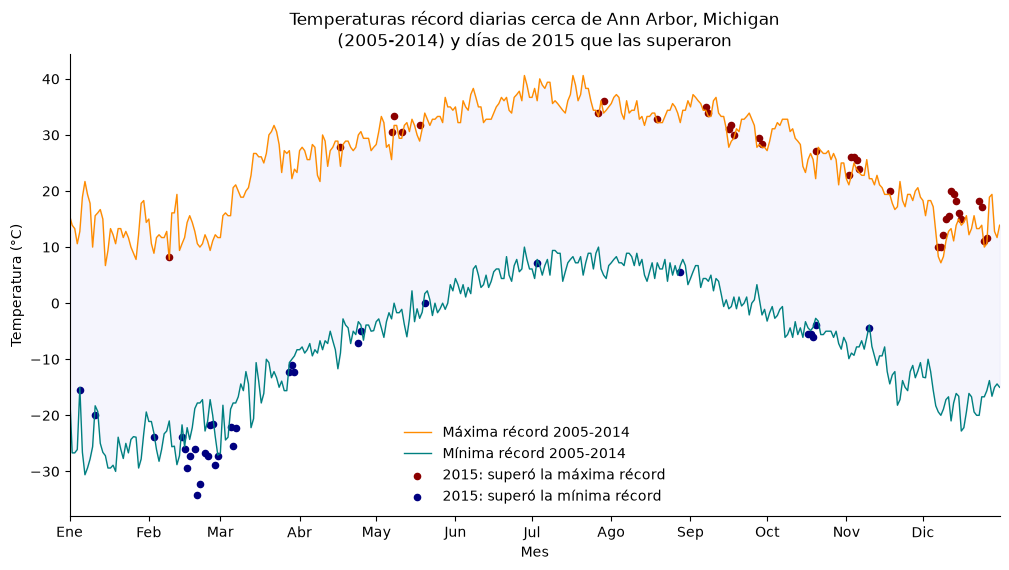

In [22]:
#Leemos los datos
df = pd.read_csv('../data/fb441e62df2d58994928907a91895ec62c2c42e6cd075c2700843b89.csv')
#Nombre a las columnas
df.columns = ['id','date','element','value']

#La fecha está en texto, hay que pasarla a fechas reales
df['date']=pd.to_datetime(df['date'])

#La temperatura está en decimas de grado
df['value'] = df['value']/10

#Crea columna año y columna dia
df['año'] = df['date'].dt.year
df['dia']=df['date'].dt.strftime('%m-%d')

#Saco los 29 de febrero ya que son un dato atípico
df = df[df['dia'] != '02-29']

#periodo 2005-2014 y el año 2015
historico = df[(df['año']>=2005) & (df['año']<=2014)]
a2015 = df[df['año']==2015]

# Valor más alto (max) o el as bajo (min)
record_max = historico[historico['element']== 'TMAX'].groupby('dia')['value'].max()
record_min = historico[historico['element']=='TMIN'].groupby('dia')['value'].min()

max_2015 = a2015[a2015['element']=='TMAX'].groupby('dia')['value'].max()
min_2015 = a2015[a2015['element']=='TMIN'].groupby('dia')['value'].min()

# Todo en una sola tabla
tabla = pd.DataFrame({
    'record_max': record_max,
    'record_min': record_min,
    'max_2015': max_2015,
    'min_2015': min_2015,
})

# Se nuemran los dáas 0 a 364 para usarlos en el eje de las x
tabla['x'] = range(len(tabla))

# Días en 2015 que rompieron record
r_max = tabla[tabla['max_2015']>tabla['record_max']]
r_min = tabla[tabla['min_2015']<tabla['record_min']]

# Gráfico
fig, ax = plt.subplots(figsize=(12, 6))


#lineas de records 2005-2014
ax.plot(tabla['x'], tabla['record_max'], color='darkorange', linewidth=1,
        label='Máxima récord 2005-2014')
ax.plot(tabla['x'], tabla['record_min'], color='teal', linewidth=1,
        label='Mínima récord 2005-2014')

# Sombreado entre las dos líneas
ax.fill_between(tabla['x'], tabla['record_min'], tabla['record_max'],
                color='lavender', alpha=0.4)

#puntos que superaron los records
ax.scatter(r_max['x'], r_max['max_2015'], color='darkred', s=20,
           label='2015: superó la máxima récord')
ax.scatter(r_min['x'], r_min['min_2015'], color='navy', s=20,
           label='2015: superó la mínima récord')

# Mejora de lectura
inicio_meses = [0, 31, 59, 90, 120, 151, 181, 212, 243, 273, 304, 334]
meses = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']

ax.set_xticks(inicio_meses)
ax.set_xticklabels(meses)
ax.set_xlim(0, 364)

# Titulo
ax.set_title('Temperaturas récord diarias cerca de Ann Arbor, Michigan\n'
             '(2005-2014) y días de 2015 que las superaron')
ax.set_xlabel('Mes')
ax.set_ylabel('Temperatura (°C)')

# leyenda
ax.legend(loc='lower center', frameon=False)

# Quitamos los bordes de arriba y de la derecha
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.show()